# DL4STG_PA2 Q2 — Motion or Memory?
Two GPUs: seed 0 on GPU 0, seed 1 on GPU 1. Read README.md. Training is still required. Run stages in order and inspect the displayed outputs between stages. Preserve outputs and Git history across sessions.

In [1]:
from pathlib import Path
import shutil, zipfile, os
DEST=Path("/kaggle/working/DL4STG_PA2_Q2")
if not DEST.exists():
    candidates=list(Path("/kaggle/input").rglob("pipeline.py"))
    candidates=[p for p in candidates if (p.parent/"core.py").exists() and (p.parent/"README.md").exists()]
    if len(candidates)==1:
        shutil.copytree(candidates[0].parent,DEST)
    else:
        archives=list(Path("/kaggle/input").rglob("DL4STG_PA2_Q2_Run_Package.zip"))
        if len(archives)!=1: raise RuntimeError("Attach exactly one extracted Q2 package or the named package ZIP.")
        with zipfile.ZipFile(archives[0]) as z: z.extractall(DEST.parent)
assert (DEST/"pipeline.py").exists()
os.chdir(DEST)
print(DEST)
import torch
print(torch.__version__, torch.cuda.device_count())
assert torch.cuda.device_count()>=1, "Enable GPU T4 x2 in notebook settings"

/kaggle/working/DL4STG_PA2_Q2
2.11.0+cu128 2


In [2]:
import importlib.util, subprocess, sys
packages={"cv2":"opencv-python-headless","matplotlib":"matplotlib","PIL":"pillow","reportlab":"reportlab"}
missing=[v for k,v in packages.items() if importlib.util.find_spec(k) is None]
if missing: subprocess.run([sys.executable,"-m","pip","install",*missing],check=True)
import torchvision
print("torchvision", torchvision.__version__)
def stage(name):
    subprocess.run([sys.executable,"pipeline.py",name],check=True)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 10.2 MB/s  0:00:00
torchvision 0.26.0+cu128


{
  "status": "passed",
  "A_parameters": 480784,
  "D_parameters": 480784,
  "A_reach_pixels_Linf": 8,
  "D_reach_pixels_Linf": 16,
  "synthetic_symmetrisation_gaps": {
    "M": 8.694434273353994e-16,
    "R": 1.0173286036624222e-15
  },
  "scope": "CPU correctness checks; not trained model performance"
}


100%|██████████| 819M/819M [00:51<00:00, 16.1MB/s]  


Setup finished. Inspect Figure 1 before baseline; prediction text will include its measured median.


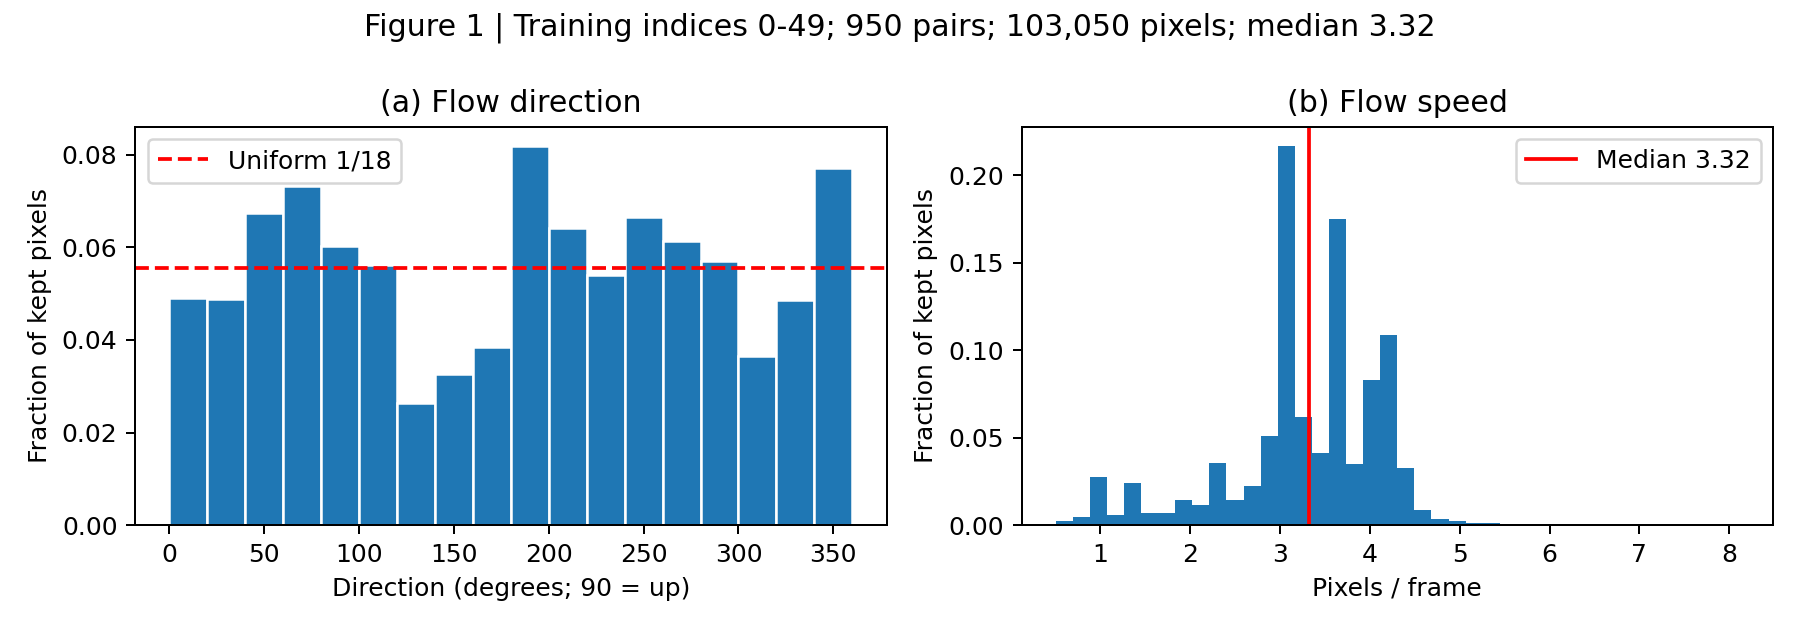

In [3]:
stage("setup")
from IPython.display import display, Image
display(Image(filename="outputs/figure1.png"))

## Before baseline tests
Inspect Figure 1. Read the Q2.5 prediction in pipeline.py. Edit it now if needed so it reflects your prediction. The next cell commits it before the stress tests. Never change it afterward.

hint: Using 'master' as the name for the initial branch. This default branch name
hint: is subject to change. To configure the initial branch name to use in all
hint: of your new repositories, which will suppress this warning, call:
hint: 
hint: 	git config --global init.defaultBranch <name>
hint: 
hint: Names commonly chosen instead of 'master' are 'main', 'trunk' and
hint: 'development'. The just-created branch can be renamed via this command:
hint: 
hint: 	git branch -m <name>


A seed 1: resume 0/30 on cuda:1
A seed 0: resume 0/30 on cuda:0
A seed 1 epoch 1/30 MSE=0.0478544 seconds=14.4
A seed 0 epoch 1/30 MSE=0.0460453 seconds=14.4
A seed 1 epoch 2/30 MSE=0.0401948 seconds=13.6
A seed 0 epoch 2/30 MSE=0.0396791 seconds=13.6
A seed 1 epoch 3/30 MSE=0.0401952 seconds=13.7
A seed 0 epoch 3/30 MSE=0.0386055 seconds=13.7
A seed 1 epoch 4/30 MSE=0.0401885 seconds=13.7
A seed 0 epoch 4/30 MSE=0.0370043 seconds=13.7
A seed 1 epoch 5/30 MSE=0.0401776 seconds=13.7
A seed 0 epoch 5/30 MSE=0.0352134 seconds=13.7
A seed 1 epoch 6/30 MSE=0.0398126 seconds=13.8
A seed 0 epoch 6/30 MSE=0.0335441 seconds=13.8
A seed 1 epoch 7/30 MSE=0.0380946 seconds=13.8
A seed 0 epoch 7/30 MSE=0.0321795 seconds=13.8
A seed 1 epoch 8/30 MSE=0.0357483 seconds=13.9
A seed 0 epoch 8/30 MSE=0.0311678 seconds=13.9
A seed 1 epoch 9/30 MSE=0.0337449 seconds=14.0
A seed 0 epoch 9/30 MSE=0.030477 seconds=14.0
A seed 1 epoch 10/30 MSE=0.0323956 seconds=14.1
A seed 0 epoch 10/30 MSE=0.0298875 seconds=

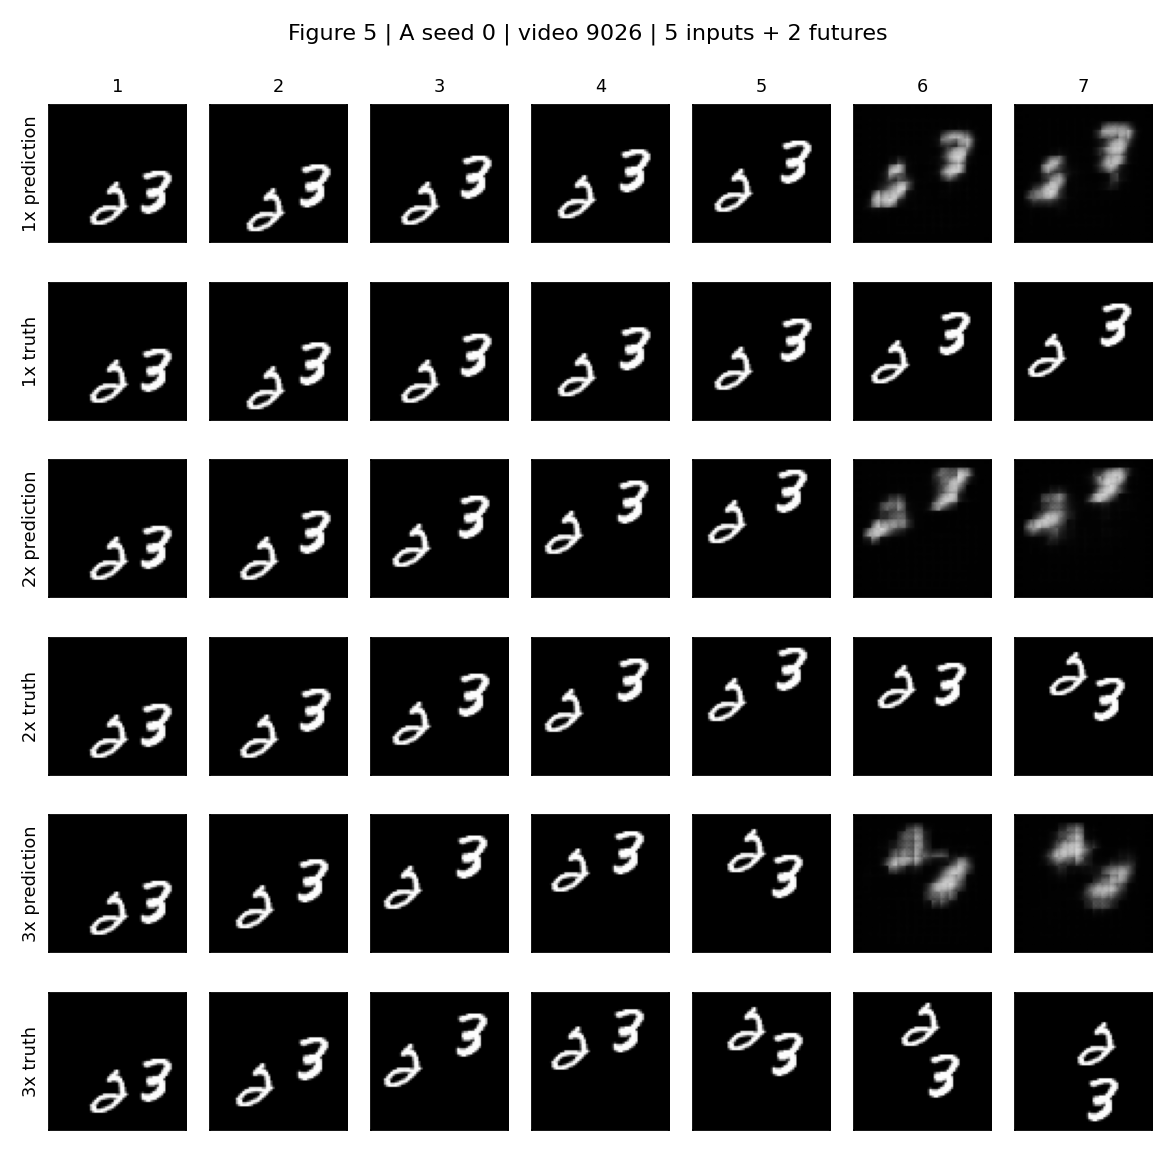

{
  "CM": [
    9613,
    9765
  ],
  "CR": [
    9279,
    9884
  ],
  "figure2": [
    9001,
    9000,
    9002
  ],
  "speed": 9026,
  "reviewed": false,
  "note": "Overlap and separation selected by connected-component heuristic; visually verify and set reviewed=true."
}


In [4]:
stage("baseline")
display(Image(filename="outputs/figure5.png"))
print(Path("outputs/selection.json").read_text())

## Before variants
Inspect Figures 2–5 and A metrics. Review the Q2.11 prediction in pipeline.py before this cell. It will be committed before any B–D training.

In [5]:
stage("variants")

B seed 0: resume 0/30 on cuda:0
B seed 1: resume 0/30 on cuda:1
B seed 1 epoch 1/30 MSE=0.0478725 seconds=14.7
B seed 0 epoch 1/30 MSE=0.0460457 seconds=14.7
B seed 1 epoch 2/30 MSE=0.0401978 seconds=14.3
B seed 0 epoch 2/30 MSE=0.0396913 seconds=14.3
B seed 1 epoch 3/30 MSE=0.040198 seconds=14.4
B seed 0 epoch 3/30 MSE=0.0386661 seconds=14.4
B seed 1 epoch 4/30 MSE=0.0401923 seconds=14.4
B seed 0 epoch 4/30 MSE=0.037155 seconds=14.4
B seed 1 epoch 5/30 MSE=0.040196 seconds=14.6
B seed 0 epoch 5/30 MSE=0.0352373 seconds=14.6
B seed 1 epoch 6/30 MSE=0.0398526 seconds=14.6
B seed 0 epoch 6/30 MSE=0.0336696 seconds=14.6
B seed 1 epoch 7/30 MSE=0.0381536 seconds=14.7
B seed 0 epoch 7/30 MSE=0.0323568 seconds=14.7
B seed 1 epoch 8/30 MSE=0.0357782 seconds=14.8
B seed 0 epoch 8/30 MSE=0.0312655 seconds=14.8
B seed 1 epoch 9/30 MSE=0.0335446 seconds=14.9
B seed 0 epoch 9/30 MSE=0.0305444 seconds=14.9
B seed 1 epoch 10/30 MSE=0.031649 seconds=14.8
B seed 0 epoch 10/30 MSE=0.029989 seconds=14.8

In [6]:
stage("final")
print(Path("outputs/completion_status.json").read_text())

{"model": "symB", "seed": 0, "parameters": 480784, "E5_1": 0.02265756204724312, "E5_2": 0.04626166447997093, "E2_1": 0.019219715148210526, "E2_2": 0.042817480862140656, "E2_3": 0.0491708405315876, "train_seconds": 14.733828611333319, "inference_seconds": 3.198631046999253, "hardware": "Tesla T4", "MSE1": 0.017365386709570885, "MSE2": 0.021074041724205017, "MSE3": 0.023334193974733353, "MSE4": 0.025018401443958282, "MSE5": 0.026495791971683502, "CM": 7.637655718978134e-17, "EM": 0.022657563909888268, "CR": 6.207624552507479e-17, "ER": 0.022657563909888268}
{"model": "symB", "seed": 1, "parameters": 480784, "E5_1": 0.021054517477750778, "E5_2": 0.04889668896794319, "E2_1": 0.017669688910245895, "E2_2": 0.044616322964429855, "E2_3": 0.05154087767004967, "train_seconds": 14.71797940979997, "inference_seconds": 3.1469878619991505, "hardware": "Tesla T4", "MSE1": 0.015944598242640495, "MSE2": 0.019394779577851295, "MSE3": 0.02166574075818062, "MSE4": 0.023360442370176315, "MSE5": 0.024907026

## Visual review and written analysis
Follow README.md. Fill review.json; verify overlap/separation in selection.json and set reviewed=true only after checking. Regenerate figures if the selected video IDs change. Keep CM/CR IDs fixed. Add your real public repository URL and actual AI edits. The PDF remains marked incomplete until these requirements are met.

In [ ]:
# After completing review.json and selection.json:
# stage("report")
# stage("package")

## Save recovery backup
Run this cell periodically, especially before the session ends. Save a Kaggle Version with outputs, or download this backup. It includes checkpoint and Git history but not the 800 MB dataset. A local ZIP alone is not durable until you save/download it.

In [7]:
from datetime import datetime
backup=Path("/kaggle/working")/("Q2_Recovery_"+datetime.now().strftime("%Y%m%d_%H%M%S")+".zip")
with zipfile.ZipFile(backup,"w",zipfile.ZIP_DEFLATED) as z:
    for p in DEST.rglob("*"):
        rel=p.relative_to(DEST)
        if p.is_file() and "data" not in rel.parts and "__pycache__" not in rel.parts and p.suffix!=".zip":
            z.write(p,Path("DL4STG_PA2_Q2")/rel)
print(backup)
from IPython.display import FileLink
display(FileLink(str(backup)))

/kaggle/working/Q2_Recovery_20261027_092811.zip


/kaggle/working/Q2_Recovery_20261027_092811.zip

## Restore a saved recovery ZIP in a new session
Attach your recovery ZIP as a Kaggle Dataset. Extract it to /kaggle/working BEFORE running the setup/copy cell above. Keep the DL4STG_PA2_Q2 folder name and its .git history. Do not extract an older backup over an active run. The dataset can be downloaded again in setup; completed model runs resume or skip.